# 04 — Dynamic Panels: LSDVC — Exercise Solutions

Solutions to the exercises from the LSDVC tutorial notebook.

In [1]:
# Setup
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

project_root = Path("../../..").resolve()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from panelbox.models.dynamic.lsdvc import LSDVC
from panelbox.models.static.fixed_effects import FixedEffects
from panelbox.datasets.load import load_grunfeld, load_abdata

plt.rcParams.update({
    "figure.figsize": (10, 6),
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

warnings.filterwarnings("ignore", category=UserWarning)
print("Setup complete.")

Setup complete.


---
## Exercise 1: LSDVC with abdata

Load the `abdata` dataset and estimate LSDVC with `n` (employment) as the dependent variable and `w` (wage) and `k` (capital) as covariates. Use entity=`ind`, time=`year`. Compare with FE.

In [2]:
# Load abdata
abdata = load_abdata()
print(f"abdata: {abdata.shape[0]} obs, {abdata['ind'].nunique()} firms, {abdata['year'].nunique()} years")
print(f"Columns: {abdata.columns.tolist()[:10]}...")
abdata[["ind", "year", "n", "w", "k"]].head(10)

abdata: 1031 obs, 9 firms, 9 years
Columns: ['c1', 'ind', 'year', 'emp', 'wage', 'cap', 'indoutpt', 'n', 'w', 'k']...


,ind,year,n,w,k
0,7.0,1977.0,1.617604,2.576543,-0.528650
1,7.0,1978.0,1.722767,2.509746,-0.459182
2,7.0,1979.0,1.612433,2.552526,-0.389936
3,7.0,1980.0,1.550749,2.624951,-0.482724
4,7.0,1981.0,1.409278,2.659539,-0.678062
5,7.0,1982.0,1.152469,2.699218,-0.860620
6,7.0,1983.0,1.077048,2.623102,-0.936493
7,7.0,1977.0,4.267163,2.694012,2.829459
8,7.0,1978.0,4.257639,2.646430,2.847360
9,7.0,1979.0,4.261524,2.704939,2.864558


In [3]:
# FE estimation with manual lag
ab_sorted = abdata.sort_values(["ind", "year"]).copy()
ab_sorted["n_lag"] = ab_sorted.groupby("ind")["n"].shift(1)
ab_fe = ab_sorted.dropna(subset=["n_lag"])

fe_ab = FixedEffects("n ~ n_lag + w + k", ab_fe, "ind", "year")
res_fe_ab = fe_ab.fit(cov_type="clustered")
print("=== Fixed Effects ===")
print(res_fe_ab.summary())

=== Fixed Effects ===
                       Fixed Effects Estimation Results                       
Formula: n ~ n_lag + w + k
Model:   Fixed Effects
------------------------------------------------------------------------------
No. Observations:               1,022
No. Entities:                       9
No. Time Periods:                 205
Degrees of Freedom:             1,010
R-squared:                     0.8806
Adj. R-squared:                0.8793
R-squared (within):            0.8806
R-squared (between):           1.0000
R-squared (overall):           0.8871
Standard Errors:            clustered
F-statistic (FE vs OLS):      57.3779
F-test p-value:                0.0000
Variable        Coef.        Std.Err.     t        P>|t|    [0.025     0.975]    
------------------------------------------------------------------------------
n_lag               -0.0314      0.0372  -0.844  0.3988   -0.1043    0.0416 
w                   -0.5963      0.2768  -2.154  0.0315   -1.1396   -0.0530 

In [4]:
# LSDVC estimation
lsdvc_ab = LSDVC("n ~ w + k", abdata, "ind", "year",
                 initial_estimator="ab", bias_order=2)
res_lsdvc_ab = lsdvc_ab.fit(n_bootstrap=200, seed=42)
print("=== LSDVC ===")
print(res_lsdvc_ab.summary())

=== LSDVC ===
                           LSDVC Estimation Results                           
Formula: n ~ w + k
Model:   LSDVC
Initial Estimator:                 AB
Bias Correction Order:              2
Convergence:                      Yes (4 iterations)
------------------------------------------------------------------------------
No. Observations:               1,022
No. Entities:                       9
No. Time Periods:                 116
Sigma^2:                       0.2050
Standard Errors:            bootstrap
Bootstrap Replications:           200
Variable        Coef.        Std.Err.     z        P>|z|    [0.025     0.975]    
------------------------------------------------------------------------------
L1.n                -0.0229      0.0099  -2.308  0.0210   -0.0360    0.0037 *
w                   -0.5963      0.0801  -7.445  0.0000   -0.7510   -0.4382 ***
k                    0.8610      0.0106  81.241  0.0000    0.8382    0.8801 ***
Signif. codes:  0 '***' 0.001 '**' 0.0

In [5]:
# Comparison
print("=" * 55)
print("  abdata: FE vs LSDVC")
print("=" * 55)
print(f"{'Variable':<12} {'FE':>12} {'LSDVC':>12}")
print("-" * 55)
for fe_name, lsdvc_name in [("n_lag", "L1.n"), ("w", "w"), ("k", "k")]:
    print(f"{lsdvc_name:<12} {res_fe_ab.params[fe_name]:>12.4f} {res_lsdvc_ab.params[lsdvc_name]:>12.4f}")
print("=" * 55)
print(f"\nBias correction on lagged employment: {res_lsdvc_ab.bias_correction['L1.n']:.4f}")

  abdata: FE vs LSDVC
Variable               FE        LSDVC
-------------------------------------------------------
L1.n              -0.0314      -0.0229
w                 -0.5963      -0.5963
k                  0.8610       0.8610

Bias correction on lagged employment: -0.0084


---
## Exercise 2: Bias Order Comparison with Grunfeld

Estimate LSDVC with all three bias orders (1, 2, 3) and plot how the corrected $\hat{\rho}$ changes.

<>:25: SyntaxWarning: invalid escape sequence '\h'
<>:25: SyntaxWarning: invalid escape sequence '\h'
/tmp/ipykernel_2021834/3911918807.py:25: SyntaxWarning: invalid escape sequence '\h'
  ax.set_ylabel("$\hat{\\rho}$")


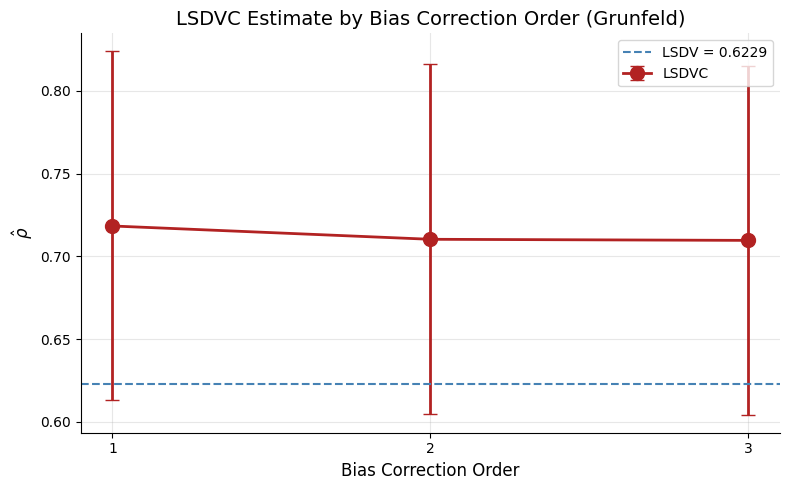


With T=19, differences between orders are small.
Order 2 is recommended as a good balance between accuracy and stability.


In [6]:
data = load_grunfeld()

orders = [1, 2, 3]
rho_by_order = {}
for order in orders:
    model = LSDVC("invest ~ value + capital", data, "firm", "year",
                  initial_estimator="ab", bias_order=order)
    res = model.fit(n_bootstrap=300, seed=42)
    rho_by_order[order] = {
        "rho": res.params["L1.invest"],
        "se": res.std_errors["L1.invest"],
        "lsdv": res.lsdv_params["L1.invest"],
    }

# Plot
fig, ax = plt.subplots(figsize=(8, 5))
rhos = [rho_by_order[o]["rho"] for o in orders]
ses = [rho_by_order[o]["se"] for o in orders]
lsdv_val = rho_by_order[1]["lsdv"]

ax.errorbar(orders, rhos, yerr=[1.96 * s for s in ses], fmt="o-", 
            color="firebrick", capsize=5, linewidth=2, markersize=10, label="LSDVC")
ax.axhline(lsdv_val, color="steelblue", linestyle="--", linewidth=1.5, label=f"LSDV = {lsdv_val:.4f}")
ax.set_xlabel("Bias Correction Order")
ax.set_ylabel("$\hat{\\rho}$")
ax.set_title("LSDVC Estimate by Bias Correction Order (Grunfeld)")
ax.set_xticks(orders)
ax.legend()
plt.tight_layout()
plt.show()

print("\nWith T=19, differences between orders are small.")
print("Order 2 is recommended as a good balance between accuracy and stability.")

---
## Exercise 3: Monte Carlo with N=4 (Extreme Small-N)

Run a Monte Carlo simulation with only N=4 entities to test LSDVC in an extreme case.

In [7]:
def simulate_ar1_panel(N, T, rho, sigma_alpha=1.0, sigma_eps=1.0, seed=None):
    rng = np.random.default_rng(seed)
    alpha = rng.normal(0, sigma_alpha, N)
    y = np.zeros((N, T + 1))
    y[:, 0] = alpha / (1 - rho) + rng.normal(0, sigma_eps / np.sqrt(1 - rho**2), N)
    for t in range(1, T + 1):
        y[:, t] = rho * y[:, t - 1] + alpha + rng.normal(0, sigma_eps, N)
    rows = []
    for i in range(N):
        for t in range(1, T + 1):
            rows.append({"entity": i, "time": t, "y": y[i, t], "y_lag": y[i, t - 1]})
    return pd.DataFrame(rows)

def fe_rho(df):
    means = df.groupby("entity")[["y", "y_lag"]].transform("mean")
    y_w = df["y"] - means["y"]
    x_w = df["y_lag"] - means["y_lag"]
    return (x_w * y_w).sum() / (x_w ** 2).sum()

true_rho = 0.5
N_small = 4
T_mc = 10
n_replicas = 100

results_mc = {"fe": [], "ah": [], "ab": [], "bb": []}

print(f"Monte Carlo: N={N_small}, T={T_mc}, rho={true_rho}, MC={n_replicas}")
print("Running...")

for rep in range(n_replicas):
    df_mc = simulate_ar1_panel(N_small, T_mc, true_rho, seed=rep)
    results_mc["fe"].append(fe_rho(df_mc))
    
    df_r = df_mc.rename(columns={"entity": "ent", "time": "t"})
    df_r["x"] = np.random.default_rng(rep).normal(0, 1, len(df_r))
    
    for est in ["ah", "ab", "bb"]:
        try:
            model = LSDVC("y ~ x", df_r, "ent", "t", initial_estimator=est, bias_order=2)
            res = model.fit(n_bootstrap=0)
            results_mc[est].append(res.params["L1.y"])
        except Exception:
            results_mc[est].append(np.nan)
    
    if (rep + 1) % 25 == 0:
        print(f"  ... {rep + 1}/{n_replicas}")

print("Done!")

Monte Carlo: N=4, T=10, rho=0.5, MC=100
Running...


  ... 25/100


  ... 50/100


  ... 75/100


  ... 100/100
Done!


In [8]:
# Results table
print("=" * 70)
print(f"  Monte Carlo Results: N={N_small} (extreme small-N)")
print("=" * 70)
print(f"{'Estimator':<12} {'Mean':>10} {'Bias':>10} {'Std.Dev':>10} {'RMSE':>10}")
print("-" * 70)

for name in ["fe", "ah", "ab", "bb"]:
    vals = np.array(results_mc[name])
    vals = vals[~np.isnan(vals)]
    bias = np.mean(vals) - true_rho
    sd = np.std(vals)
    rmse = np.sqrt(np.mean((vals - true_rho)**2))
    label = "FE" if name == "fe" else f"LSDVC({name.upper()})"
    print(f"{label:<12} {np.mean(vals):>10.4f} {bias:>10.4f} {sd:>10.4f} {rmse:>10.4f}")

print("=" * 70)
print("\nWith N=4, all estimators are noisy.")
print("LSDVC still reduces bias vs FE, but variance is higher.")
print("The initial estimator matters more here since GMM is less reliable with tiny N.")

  Monte Carlo Results: N=4 (extreme small-N)
Estimator          Mean       Bias    Std.Dev       RMSE
----------------------------------------------------------------------
FE               0.3342    -0.1658     0.1547     0.2268
LSDVC(AH)        0.4626    -0.0374     0.1792     0.1830
LSDVC(AB)        0.4626    -0.0374     0.1792     0.1830
LSDVC(BB)        0.4626    -0.0374     0.1792     0.1830

With N=4, all estimators are noisy.
LSDVC still reduces bias vs FE, but variance is higher.
The initial estimator matters more here since GMM is less reliable with tiny N.


<>:14: SyntaxWarning: invalid escape sequence '\h'
<>:14: SyntaxWarning: invalid escape sequence '\h'
/tmp/ipykernel_2021834/2674749411.py:14: SyntaxWarning: invalid escape sequence '\h'
  ax.set_xlabel("$\hat{\\rho}$")


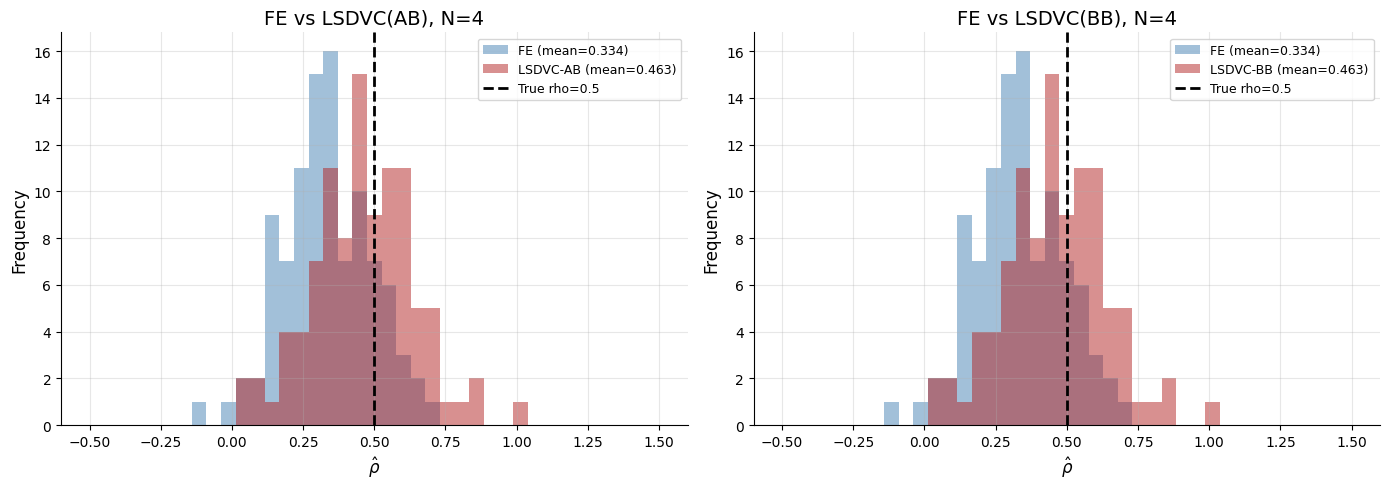

Even with only 4 entities, LSDVC reduces the downward bias of FE.


In [9]:
# Histogram comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# FE vs LSDVC(AB)
bins = np.linspace(-0.5, 1.5, 40)
for ax, est_name, est_label in [(axes[0], "ab", "AB"), (axes[1], "bb", "BB")]:
    fe_vals = np.array(results_mc["fe"])
    est_vals = np.array(results_mc[est_name])
    est_vals = est_vals[~np.isnan(est_vals)]
    
    ax.hist(fe_vals, bins=bins, alpha=0.5, label=f"FE (mean={np.mean(fe_vals):.3f})", color="steelblue")
    ax.hist(est_vals, bins=bins, alpha=0.5, label=f"LSDVC-{est_label} (mean={np.nanmean(est_vals):.3f})", color="firebrick")
    ax.axvline(true_rho, color="black", linewidth=2, linestyle="--", label=f"True rho={true_rho}")
    ax.set_xlabel("$\hat{\\rho}$")
    ax.set_ylabel("Frequency")
    ax.set_title(f"FE vs LSDVC({est_label}), N={N_small}")
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()
print("Even with only 4 entities, LSDVC reduces the downward bias of FE.")